<a href="https://colab.research.google.com/github/mohammadbadi/CrimeAnalytics_Clustering/blob/main/Code%20Sections/6.1%203D%20Visualizations%20of%20Top%205%20Clusters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Code Sections/6.1 3D Visualizations of Top 5 Clusters - Approach 1.ipynb**

In [ ]:
!pip install -q kaleido  # Uncomment if kaleido is not installed


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 10.6 MB/s eta 0:00:00


""

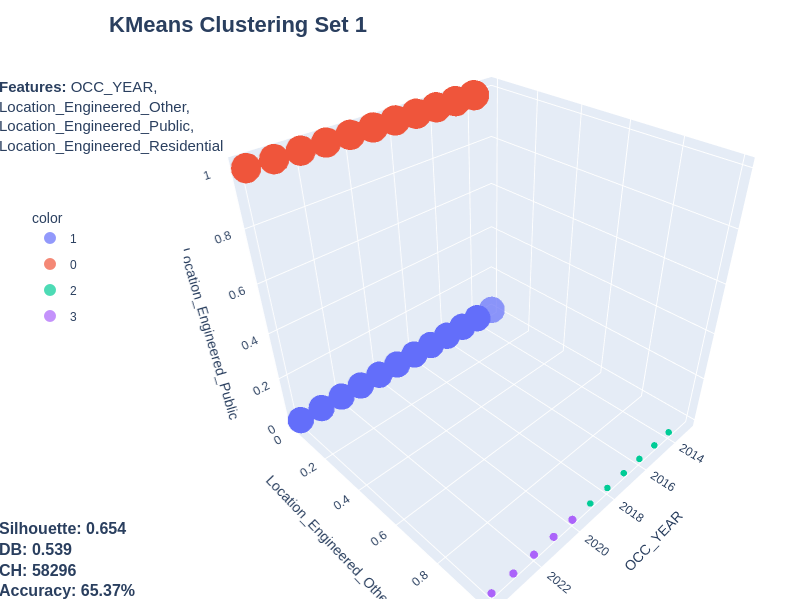

""

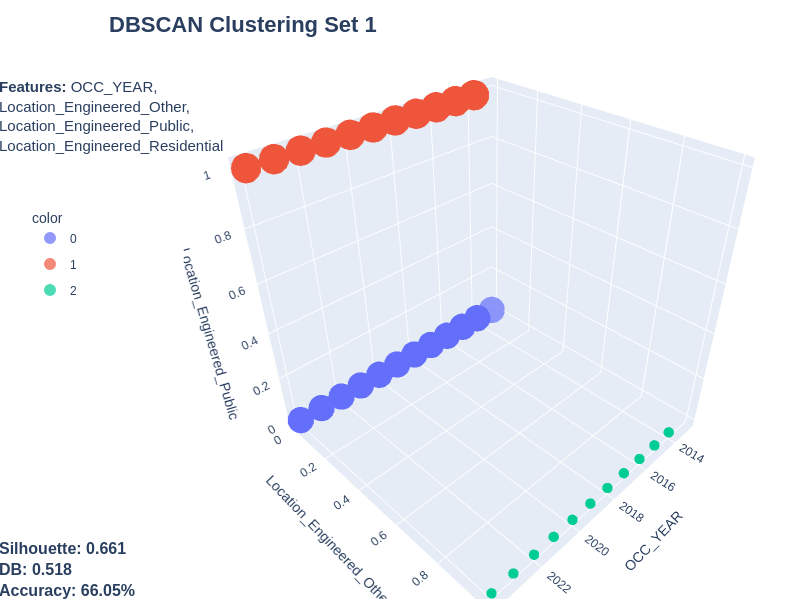

""

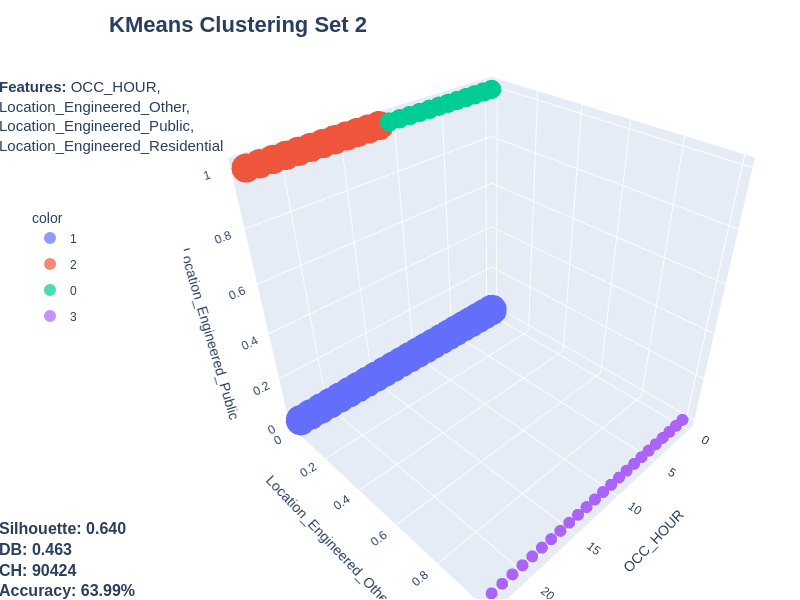

""

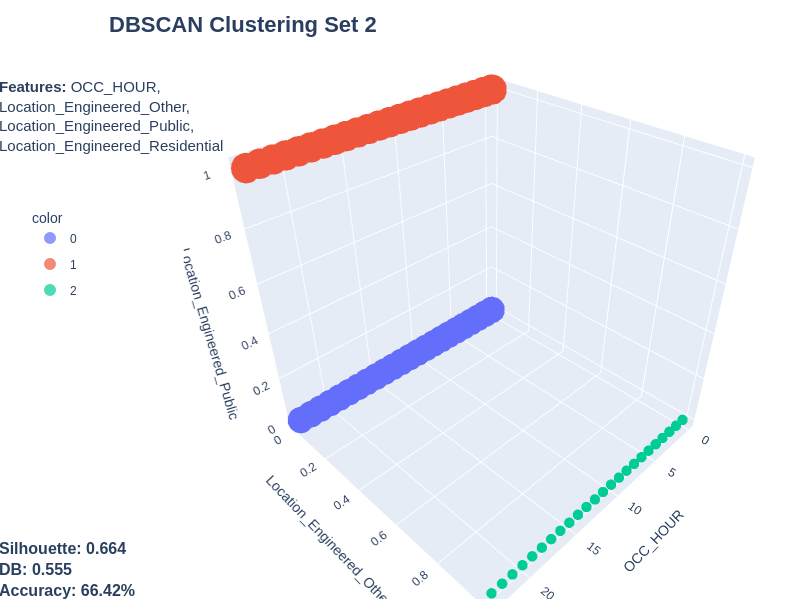

""

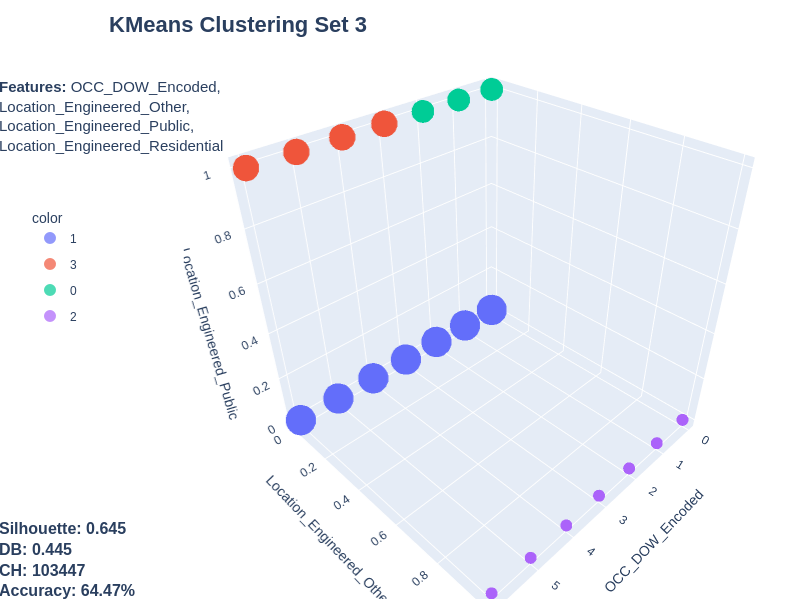

""

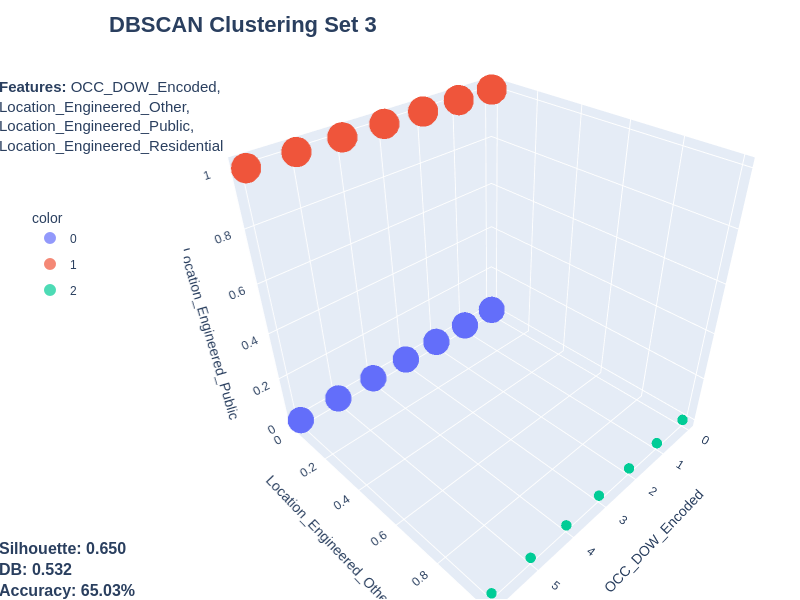

""

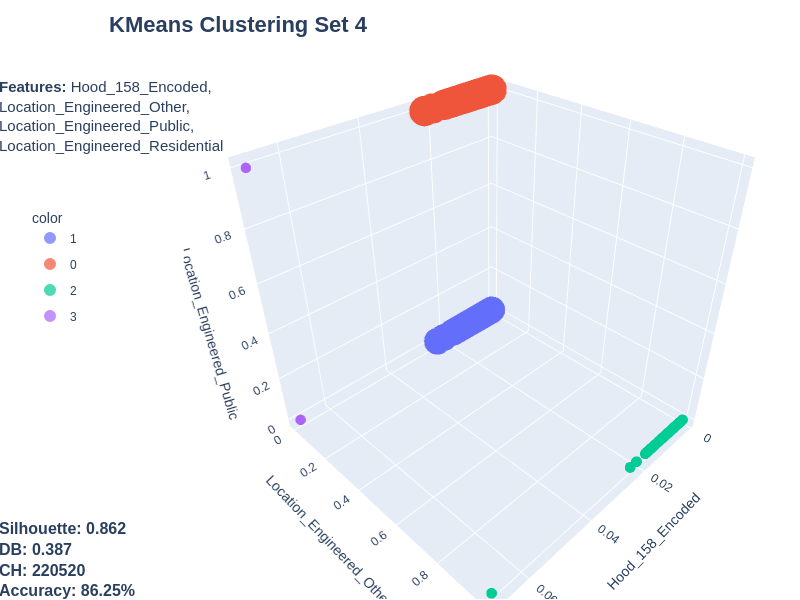

""

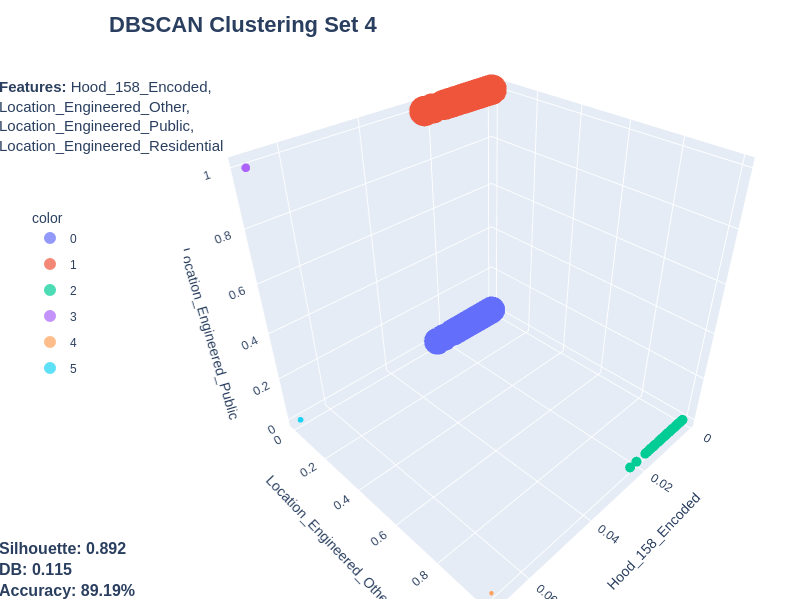

""

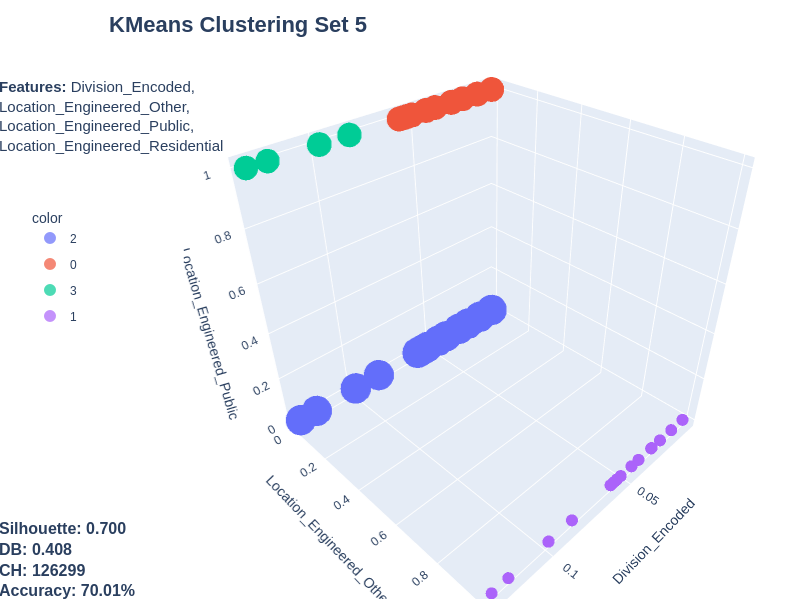

""

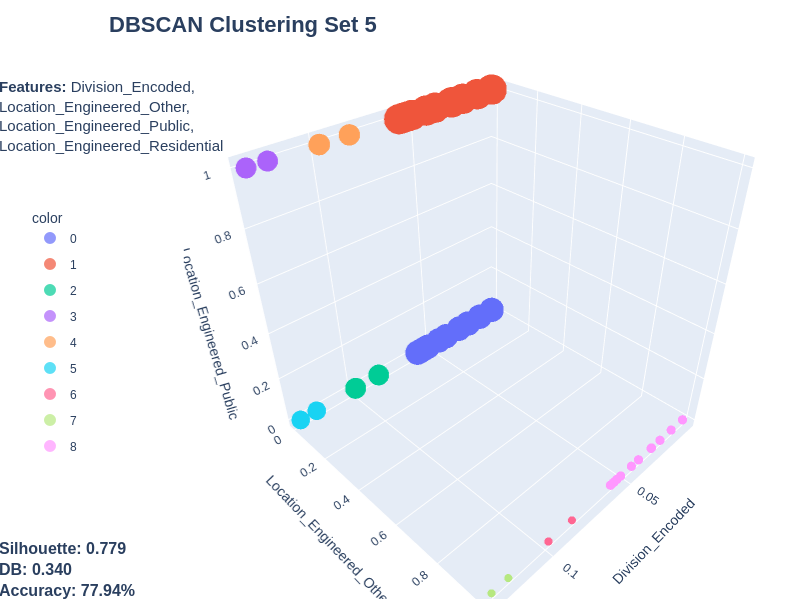

In [ ]:
import pandas as pd
import plotly.express as px
from IPython.display import display, HTML
import ast, html, base64, os, copy

#!pip install -q kaleido  # Uncomment if kaleido is not installed

# Global variable to accumulate interactive HTML (if needed)
all_html = ""

# Display function for interactive models (800x600px container)
def display_interactive_table(title, fig):
    global all_html
    fig.update_layout(autosize=True, height=580)  # Plot area height 580px
    fig.update_traces(marker_line_width=0)
    # Generate interactive HTML with modebar visible
    fig_html = fig.to_html(full_html=False, include_plotlyjs='cdn', config={"displayModeBar": True})
    fig_html_escaped = html.escape(fig_html)
    iframe_html = f"""<iframe srcdoc="{fig_html_escaped}" style="position:relative; width:800px; height:610px; border:none;"></iframe>"""
    html_table = f"""
      <table style="border-collapse: collapse; width:800px; margin:auto; border:2px solid black;">
        <tbody>
          <tr>
              <td style="padding:0; margin:0;">{iframe_html}</td>
          </tr>
        </tbody>
      </table>
      <br>
      """

    all_html += html_table
    display(HTML(html_table))

# Functions to save and display static images
def file_to_base64(filepath):
    with open(filepath, "rb") as f:
        data = f.read()
    return base64.b64encode(data).decode('utf-8')

def display_static_image(filepath):
    img_base64 = file_to_base64(filepath)
    html_table = f"""
    <table style="border-collapse: collapse; width:800px; margin:auto;">
      <tr>
         <td style="border: 1px solid #dddddd; text-align:center;">
            <img src="data:image/png;base64,{img_base64}" style="width:100%; border:1px solid #dddddd;" />
         </td>
      </tr>
    </table>
    <br>
    """
    display(HTML(html_table))

# Load datasets
url = "https://raw.githubusercontent.com/mohammadbadi/CrimeAnalytics_Clustering/refs/heads/main/Output_CSV/Clustering_Base_Features.csv"
url1 = "https://raw.githubusercontent.com/mohammadbadi/CrimeAnalytics_Clustering/refs/heads/main/Output_CSV/Clustering_Result_Stats.csv"
url2 = "https://raw.githubusercontent.com/mohammadbadi/CrimeAnalytics_Clustering/refs/heads/main/Output_CSV/Feature_Combo_Current_Results.csv"
features_df = pd.read_csv(url)
clustering_stats_df = pd.read_csv(url1)
clustering_results = pd.merge(features_df, clustering_stats_df, on="_id", how="left")
feature_combos = pd.read_csv(url2)

# Extract feature sets
set_names = ['4_Set_165', '4_Set_369', '4_Set_490', '4_Set_494', '4_Set_495']
feature_sets = []
for set_name in set_names:
    matched_features = feature_combos[feature_combos['Feature Set'] == set_name]['Feature_Names_String']
    if not matched_features.empty:
        features_list = ast.literal_eval(matched_features.values[0])
        feature_sets.append(features_list)

color_sequence = px.colors.qualitative.Plotly
static_outputs = []  # to store PNG filenames

# Process clustering sets (KMeans and DBSCAN)
for i in range(1, 6):
    kmeans_cluster_col = f'KMeans{i}_Cluster'
    dbscan_cluster_col = f'DBSCAN{i}_Cluster'
    features_used = feature_sets[i - 1]

    valid_kmeans_data = clustering_results[
        clustering_results[kmeans_cluster_col].notna() &
        (clustering_results[kmeans_cluster_col] != -1) &
        clustering_results[features_used[0]].notna() &
        clustering_results[features_used[1]].notna() &
        clustering_results[features_used[2]].notna()
    ]
    valid_dbscan_data = clustering_results[
        clustering_results[dbscan_cluster_col].notna() &
        (clustering_results[dbscan_cluster_col] != -1) &
        clustering_results[features_used[0]].notna() &
        clustering_results[features_used[1]].notna() &
        clustering_results[features_used[2]].notna()
    ]

    # Process KMeans data
    if not valid_kmeans_data.empty:
        cluster_sizes = valid_kmeans_data.groupby(kmeans_cluster_col).size().rename('cluster_size')
        valid_kmeans_data = valid_kmeans_data.merge(cluster_sizes, left_on=kmeans_cluster_col, right_index=True)
        fig_kmeans = px.scatter_3d(
            valid_kmeans_data,
            x=features_used[0],
            y=features_used[1],
            z=features_used[2],
            color=valid_kmeans_data[kmeans_cluster_col].astype(str),
            size='cluster_size',
            size_max=50,
            color_discrete_sequence=color_sequence
        )
        fig_kmeans.update_traces(marker_line_width=0)

        # Update layout with smaller margins and horizontal legend
        fig_kmeans.update_layout(
            margin=dict(t=20, b=1, l=30, r=1),  # Reduced top margin
            scene=dict(
                xaxis_title=features_used[0],
                yaxis_title=features_used[1],
                zaxis_title=features_used[2],
                domain=dict(x=[0.2, 1], y=[0, 1])
            ),
            legend=dict(
                orientation="v",    # Horizontal legend
                yanchor="top",      # Anchor position
                y=0.68,             # Position at top
                xanchor="left",     # Left align horizontally
                x=0,                # Left position
                itemwidth=30,       # Width of each legend item
                itemsizing="constant", # Fixed size for items
                borderwidth=0,      # Add a border
                bordercolor="gray", # Border color
                tracegroupgap=7     # Gap between legend groups
            )
        )

        # Add plot title as an annotation in the figure
        fig_kmeans.add_annotation(
            x=0.1, y=1.018, xref="paper", yref="paper",
            text=f"<b>{'KMeans Clustering Set ' + str(i)}</b>",
            showarrow=False, align="center",
            font=dict(size=22),
            bgcolor="rgba(255,255,255,0.8)",
            bordercolor="gray",
            borderwidth=0,
            borderpad=2
        )
        # Add feature names as an annotation near the top, left-aligned
        wrapped_features = "<b>Features:</b> " + ",<br>".join(features_used)
        fig_kmeans.add_annotation(
            x=-0.04, y=0.9, xref="paper", yref="paper",
            text=wrapped_features,
            showarrow=False, align="left",
            font=dict(size=15),
            bgcolor="rgba(255,255,255,0.8)",
            bordercolor="gray",
            borderwidth=0,
            borderpad=0
        )
        # Add clustering statistics as an annotation below the features annotation
        kmeans_sil = clustering_results[f'KMeans{i}_Silhouette_Score'].iloc[0]
        kmeans_db  = clustering_results[f'KMeans{i}_Davies_Bouldin_Index'].iloc[0]
        kmeans_ch  = clustering_results[f'KMeans{i}_Calinski_Harabasz_Score'].iloc[0]
        kmeans_acc = clustering_results[f'KMeans{i}_Prediction_Accuracy'].iloc[0]
        kmeans_stats = (
            f"Silhouette: {kmeans_sil:.3f}<br>"
            f"DB: {kmeans_db:.3f}<br>"
            f"CH: {kmeans_ch:.0f}<br>"
            f"Accuracy: {kmeans_acc:.2f}%"
          )
        fig_kmeans.add_annotation(
        x=-0.04, y=0, xref="paper", yref="paper",
        text=f"<b>{kmeans_stats}</b>",
        showarrow=False, align="left",
        font=dict(size=16),
        bgcolor="rgba(255,255,255,0.8)",
        bordercolor="gray",
        borderwidth=0,
        borderpad=0
        )

        # Display interactive figure
        display_interactive_table(f"KMeans Clustering Set {i}", fig_kmeans)

        # For static PNG - create a copy with different annotations
        fig_kmeans_static = copy.deepcopy(fig_kmeans)

        # Save static PNG for now (we'll improve it later)
        filename = f"kmeans_cluster_set_{i}.png"
        fig_kmeans_static.write_image(filename, width=800, height=600)
        static_outputs.append(filename)

    # Process DBSCAN data with the same improvements
    if not valid_dbscan_data.empty:
        cluster_sizes = valid_dbscan_data.groupby(dbscan_cluster_col).size().rename('cluster_size')
        valid_dbscan_data = valid_dbscan_data.merge(cluster_sizes, left_on=dbscan_cluster_col, right_index=True)
        fig_dbscan = px.scatter_3d(
            valid_dbscan_data,
            x=features_used[0],
            y=features_used[1],
            z=features_used[2],
            color=valid_dbscan_data[dbscan_cluster_col].astype(str),
            size='cluster_size',
            size_max=50,
            color_discrete_sequence=color_sequence
        )
        fig_dbscan.update_traces(marker_line_width=0)

        # Update layout with smaller margins and horizontal legend
        # For DBSCAN plots - update this section
        fig_dbscan.update_layout(
            margin=dict(t=20, b=1, l=30, r=1),  # Reduced top margin
            scene=dict(
                xaxis_title=features_used[0],
                yaxis_title=features_used[1],
                zaxis_title=features_used[2],
                domain=dict(x=[0.2, 1], y=[0, 1])
            ),
            legend=dict(
                orientation="v",    # Horizontal legend
                yanchor="top",      # Anchor position
                y=0.68,             # Position at top
                xanchor="left",     # Left align horizontally
                x=0,                # Left position
                itemwidth=30,       # Width of each legend item
                itemsizing="constant", # Fixed size for items
                borderwidth=0,      # Add a border
                bordercolor="gray", # Border color
                tracegroupgap=7     # Gap between legend groups
            )
        )
        # Add plot title as an annotation in the figure
        fig_dbscan.add_annotation(
            x=0.1, y=1.018, xref="paper", yref="paper",
            text=f"<b>{'DBSCAN Clustering Set ' + str(i)}</b>",
            showarrow=False, align="center",
            font=dict(size=22),
            bgcolor="rgba(255,255,255,0.8)",
            bordercolor="gray",
            borderwidth=0,
            borderpad=2
        )
        # Add feature names as an annotation near the top, left-aligned
        wrapped_features = "<b>Features:</b> " + ",<br>".join(features_used)
        fig_dbscan.add_annotation(
            x=-0.04, y=0.90, xref="paper", yref="paper",
            text=wrapped_features,
            showarrow=False, align="left",
            font=dict(size=15),
            bgcolor="rgba(255,255,255,0.8)",
            bordercolor="gray",
            borderwidth=0,
            borderpad=0
        )
        # Add clustering statistics as an annotation below the features annotation
        dbscan_sil = clustering_results[f'DBSCAN{i}_Silhouette_Score'].iloc[0]
        dbscan_db  = clustering_results[f'DBSCAN{i}_Davies_Bouldin_Index'].iloc[0]
        dbscan_acc = clustering_results[f'DBSCAN{i}_Prediction_Accuracy'].iloc[0]
        dbscan_stats = (
                  f"Silhouette: {dbscan_sil:.3f}<br>"
                  f"DB: {dbscan_db:.3f}<br>"
                  f"Accuracy: {dbscan_acc:.2f}%"
                )
        fig_dbscan.add_annotation(
        x=-0.04, y=0, xref="paper", yref="paper",
        text=f"<b>{dbscan_stats}</b>",
        showarrow=False, align="left",
        font=dict(size=16),
        bgcolor="rgba(255,255,255,0.8)",
        bordercolor="gray",
        borderwidth=0,
        borderpad=0
        )

        # Display interactive figure
        display_interactive_table(f"DBSCAN Clustering Set {i}", fig_dbscan)

        # For static PNG - create a copy with different annotations
        fig_dbscan_static = copy.deepcopy(fig_dbscan)

        # Save static PNG for now (we'll improve it later)
        filename = f"dbscan_cluster_set_{i}.png"
        fig_dbscan_static.write_image(filename, width=800, height=600)
        static_outputs.append(filename)

# After all interactive figures are displayed, show all static PNG images.
for filepath in static_outputs:
    if os.path.exists(filepath):
        display_static_image(filepath)
    else:
        display(HTML(f"<p style='text-align:center; color:red;'>Error: {filepath} not found.</p>"))

# Optionally, save all interactive HTML to a file.
with open("interactive_visuals.html", "w") as f:
    f.write(all_html)

display(HTML("<h3 style='text-align:center;'>Interactive HTML and static PNG images have been saved.</h3>"))